<a href="https://colab.research.google.com/github/EthanFerba/IDX-Exchange-Data-Science/blob/main/Feature_eng.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# First import the libaries
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

Import the data frame

In [2]:
rdf = pd.read_csv("Completedf.csv")
print("Dataset shape:", rdf.shape)
rdf.head()

Dataset shape: (65782, 46)


,ClosePrice,Latitude,Longitude,PropertyType,LivingArea,CloseDate,ListPrice,DaysOnMarket,ListOfficeName,ListingContractDate,...,Flooring_Tile,Flooring_Vinyl,Flooring_Wood,Flooring_Missing,Flooring_SeeRemarks,Log_ClosePrice,Log_ListPrice,Log_LivingArea,Log_LotSizeSquareFeet,Log_LotSizeArea
0,640000.0,34.235979,-117.202269,Residential,2070.0,2022-01-10,565000.0,13.0,Label Realty Group,2021-10-12,...,0,0,0,1,0,13.369225,13.244583,7.635787,8.130942,8.130942
1,438000.0,34.114130,-117.442493,Residential,1174.0,2022-03-23,349999.0,3.0,INTERNATIONAL REAL ESTATE SVCS,2021-10-13,...,0,0,0,1,0,12.989976,12.765688,7.069023,9.200391,9.200391
2,399990.0,39.767729,-121.586400,Residential,1422.0,2022-01-19,399990.0,63.0,"3Tree Realty, Inc.",2021-04-09,...,0,0,0,1,0,12.899197,12.899197,7.260523,9.409027,9.409027
3,1050000.0,34.164901,-118.319259,Residential,1312.0,2022-03-08,1103000.0,33.0,"Ingenious Asset Group, Inc.",2021-10-13,...,0,0,0,0,0,13.864302,13.913545,7.180070,8.875287,8.875287
4,275000.0,34.405539,-116.948065,Residential,1578.0,2022-03-29,272500.0,98.0,Dynasty Real Estate,2021-10-13,...,0,1,0,0,0,12.524530,12.515398,7.364547,10.244450,10.244450


Just doing a double check to make sure that everything is looking the way I want it too

In [3]:
rdf.isna().mean() * 100

,0
ClosePrice,0.0
Latitude,0.0
Longitude,0.0
PropertyType,0.0
LivingArea,0.0
CloseDate,0.0
ListPrice,0.0
DaysOnMarket,0.0
ListOfficeName,0.0
ListingContractDate,0.0


Use the same splitting function from the data cleaning phase

In [4]:

def create_temporal_split(df, training_months_x):

    df = df.copy()
    df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

    max_close_date = df["CloseDate"].max()
    test_start_date = max_close_date.to_period("M").start_time
    test_end_date = test_start_date + pd.DateOffset(months=1)

    train_start_date = test_start_date - pd.DateOffset(
        months=training_months_x
    )

    train_mask = (
        (df["CloseDate"] >= train_start_date)
        & (df["CloseDate"] < test_start_date)
    )

    test_mask = (
        (df["CloseDate"] >= test_start_date)
        & (df["CloseDate"] < test_end_date)
    )

    df_train = df[train_mask].copy()
    df_test = df[test_mask].copy()

    print(f"--- Split Summary for X = {training_months_x} Months ---")
    print(
        f"Train: {train_start_date.date()} to "
        f"{(test_start_date - pd.Timedelta(days=1)).date()} "
        f"({len(df_train)} rows)"
    )
    print(
        f"Test:  {test_start_date.date()} to "
        f"{(test_end_date - pd.Timedelta(days=1)).date()} "
        f"({len(df_test)} rows)"
    )
    print(f"Missing CloseDate rows: {df['CloseDate'].isna().sum()}\n")

    return df_train, df_test


window_options = [3, 6, 12, 24]

for X in window_options:
    train_set, test_set = create_temporal_split(
        rdf, training_months_x=X
    )


--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0



These are the columns that we do not want to include

In [5]:
# Columns that should not be used as model features
columns_to_drop = [
    "ClosePrice",
    "Log_ClosePrice",
    "CloseDate",
    "PurchaseContractDate",
    "DaysOnMarket",
    "ListingContractDate",
    "ListOfficeName",
    "ListAgentFullName",
    "PropertyType",
    "PropertySubType",
    "ListPrice",
    "Log_ListPrice"
]


In [6]:
window_options = [3, 6, 12, 24]

In [7]:
baseline_results = []

for months in window_options:

    # Split data
    train_set, test_set = create_temporal_split(
        rdf, training_months_x=months
    )

    # Separate target
    y_train = train_set["ClosePrice"]
    y_test = test_set["ClosePrice"]

    # Remove target and leakage columns
    X_train = train_set.drop(
        columns=columns_to_drop, errors="ignore"
    )
    X_test = test_set.drop(
        columns=columns_to_drop, errors="ignore"
    )

    # Keep numerical features only
    X_train = X_train.select_dtypes(include="number")
    X_test = X_test[X_train.columns]

    # Train Linear Regression
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_test)

    # Evaluate
    test_r2 = r2_score(y_test, predictions)

    # Record results
    baseline_results.append({
        "Training_Months": months,
        "Training_Rows": len(X_train),
        "Testing_Rows": len(X_test),
        "Test_R2": test_r2
    })

    print(f"{months}-month window: R² = {test_r2:.4f}")

--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

3-month window: R² = 0.5263
--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

6-month window: R² = 0.5310
--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

12-month window: R² = 0.5292
--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

24-month window: R² = 0.5264


Ranked R^2

In [8]:
results_df = pd.DataFrame(baseline_results)

results_df = results_df.sort_values(
    by="Test_R2",
    ascending=False
).reset_index(drop=True)

results_df

,Training_Months,Training_Rows,Testing_Rows,Test_R2
0,6,47079,7069,0.530972
1,12,54273,7069,0.529234
2,24,58713,7069,0.526381
3,3,24044,7069,0.526261


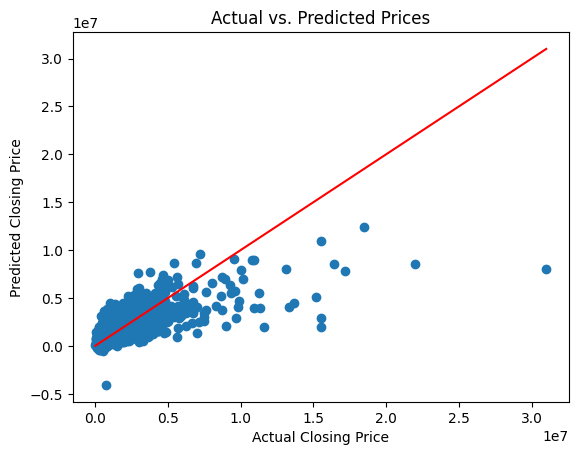

In [9]:
plt.scatter(y_test, predictions)
plt.xlabel("Actual Closing Price")
plt.ylabel("Predicted Closing Price")
plt.title("Actual vs. Predicted Prices")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.show()

# Decision Tree

### Evaluating Decision Tree Regressors
Since we are predicting a continuous target (`ClosePrice`), we will use `DecisionTreeRegressor` instead of `DecisionTreeClassifier`. We will loop through the different depths and window options to find the best configuration, maintaining the numeric-only selection.

In [10]:
dt_results = []
depths = [3, 5, 7, 11]

for months in window_options:
    train_set, test_set = create_temporal_split(rdf, training_months_x=months)

    # Target variables
    y_train = train_set["ClosePrice"]
    y_test = test_set["ClosePrice"]

    # Feature drops
    X_train = train_set.drop(columns=columns_to_drop, errors="ignore")
    X_test = test_set.drop(columns=columns_to_drop, errors="ignore")

    X_train = X_train.select_dtypes(include="number")
    X_test = X_test[X_train.columns]

    for depth in depths:
        dt_model = DecisionTreeRegressor(max_depth=depth, random_state=42)
        dt_model.fit(X_train, y_train)

        # Predict and Evaluate
        predictions = dt_model.predict(X_test)
        test_r2 = r2_score(y_test, predictions)

        dt_results.append({
            "Training_Months": months,
            "Max_Depth": depth,
            "Training_Rows": len(X_train),
            "Test_R2": test_r2
        })
        print(f"{months}-month window (Depth {depth}): R² = {test_r2:.4f}")

# Convert to DataFrame and sort by best performance
dt_results_df = pd.DataFrame(dt_results).sort_values(by="Test_R2", ascending=False).reset_index(drop=True)
display(dt_results_df.head(10))

--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

3-month window (Depth 3): R² = 0.4399
3-month window (Depth 5): R² = 0.4998
3-month window (Depth 7): R² = 0.6122
3-month window (Depth 11): R² = 0.5851
--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

6-month window (Depth 3): R² = 0.4367
6-month window (Depth 5): R² = 0.5312
6-month window (Depth 7): R² = 0.5735
6-month window (Depth 11): R² = 0.6736
--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

12-month window (Depth 3): R² = 0.4200
12-month window (Depth 5): R² = 0.5613
12-month window (Depth 7): R² = 0.6224
12-month window (Depth 11): R² = 0.5087
--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31

,Training_Months,Max_Depth,Training_Rows,Test_R2
0,6,11,47079,0.673584
1,24,11,58713,0.628956
2,24,7,58713,0.628197
3,12,7,54273,0.622406
4,3,7,24044,0.612165
5,3,11,24044,0.585066
6,6,7,47079,0.573460
7,12,5,54273,0.561337
8,24,5,58713,0.547060
9,6,5,47079,0.531249


# Random Forest

In [11]:
rf_results = []
n_vals = [50, 100, 200]
depths = [11]

for months in window_options:
    train_set, test_set = create_temporal_split(rdf, training_months_x=months)

    # Target variables
    y_train = train_set["ClosePrice"]
    y_test = test_set["ClosePrice"]

    # Feature drops
    X_train = train_set.drop(columns=columns_to_drop, errors="ignore")
    X_test = test_set.drop(columns=columns_to_drop, errors="ignore")

    X_train = X_train.select_dtypes(include="number")
    X_test = X_test[X_train.columns]

    for n in n_vals:
      for depth in depths:
        rf_model = RandomForestRegressor(n_estimators=n, max_depth=depth, random_state=42)
        rf_model.fit(X_train, y_train)

        # Predict and Evaluate
        predictions = rf_model.predict(X_test)
        test_r2 = r2_score(y_test, predictions)

        dt_results.append({
            "N value": n_vals,
            "Training_Months": months,
            "Max_Depth": depth,
            "Training_Rows": len(X_train),
            "Test_R2": test_r2
        })
        print(f"{months}-month window | N value({n}) (Depth {depth}): R² = {test_r2:.4f}")

# Convert to DataFrame and sort by best performance
dt_results_df = pd.DataFrame(dt_results).sort_values(by="Test_R2", ascending=False).reset_index(drop=True)
display(dt_results_df.head(10))

--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

3-month window | N value(50) (Depth 11): R² = 0.7401
3-month window | N value(100) (Depth 11): R² = 0.7453
3-month window | N value(200) (Depth 11): R² = 0.7458
--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

6-month window | N value(50) (Depth 11): R² = 0.7513
6-month window | N value(100) (Depth 11): R² = 0.7621
6-month window | N value(200) (Depth 11): R² = 0.7580
--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

12-month window | N value(50) (Depth 11): R² = 0.7612
12-month window | N value(100) (Depth 11): R² = 0.7729
12-month window | N value(200) (Depth 11): R² = 0.7775
--- Split Summary for X = 24 Months ---
Train: 2

,Training_Months,Max_Depth,Training_Rows,Test_R2,N value
0,12,11,54273,0.777501,"[50, 100, 200]"
1,24,11,58713,0.777072,"[50, 100, 200]"
2,24,11,58713,0.776282,"[50, 100, 200]"
3,24,11,58713,0.775779,"[50, 100, 200]"
4,12,11,54273,0.772899,"[50, 100, 200]"
5,6,11,47079,0.762129,"[50, 100, 200]"
6,12,11,54273,0.761214,"[50, 100, 200]"
7,6,11,47079,0.758033,"[50, 100, 200]"
8,6,11,47079,0.751324,"[50, 100, 200]"
9,3,11,24044,0.745770,"[50, 100, 200]"


# Feature Eng

In [12]:
import geopandas as gpd
import zipfile
from pathlib import Path

# Make a copy
rdf_features = rdf.copy().reset_index(drop=True)


# Property Features

listing_year = pd.to_datetime(
    rdf_features["ListingContractDate"], errors="coerce"
).dt.year

rdf_features["PropertyAge"] = (
    listing_year - rdf_features["YearBuilt"]
).clip(lower=0).fillna(0)

rdf_features["BathroomsPerBedroom"] = (
    rdf_features["BathroomsTotalInteger"]
    / rdf_features["BedroomsTotal"].replace(0, np.nan)
).fillna(0)


# lot Features


lot_ratio = (
    rdf_features["LotSizeSquareFeet"]
    / rdf_features["LivingArea"].replace(0, np.nan)
).fillna(0)

rdf_features["LogLotToLivingRatio"] = np.log1p(lot_ratio)


# House Features

rdf_features["NewerHome"] = (
    rdf_features["PropertyAge"] <= 5
).astype(int)

# Loading School District

zip_path = Path("DistrictAreas2425.zip")
extract_dir = Path("school_districts_extracted")

if not zip_path.exists():
    raise FileNotFoundError(
        "School district ZIP file was not found."
    )

if not list(extract_dir.rglob("*.shp")):
    extract_dir.mkdir(exist_ok=True)

    with zipfile.ZipFile(zip_path) as z:
        z.extractall(extract_dir)

shp_path = next(extract_dir.rglob("*.shp"))

districts = gpd.read_file(shp_path)

# Find column names
name_col = next(
    (c for c in districts.columns
     if c.lower().replace("_", "").startswith("districtn")),
    None
)

type_col = next(
    (c for c in districts.columns
     if c.lower().replace("_", "").startswith("districtt")),
    None
)

if name_col is None or type_col is None:
    raise ValueError(
        f"Check district columns: {list(districts.columns)}"
    )

districts = districts.rename(columns={
    name_col: "DistrictName",
    type_col: "DistrictType"
})

# Keep high school and unified districts
# DistrictType is only used for filtering
districts = districts[
    districts["DistrictType"].fillna("").str.contains(
        "high|secondary|unified", case=False
    )
].copy()

if districts.empty:
    raise ValueError("No high or unified districts found.")

districts = districts.to_crs("EPSG:4326")



# SPATIAL JOIN USING PROPERTY COORDINATES

# Only add the district name
rdf_features["OfficialSchoolDistrict"] = "Unknown"

valid_coords = (
    rdf_features["Latitude"].between(32, 42.5)
    & rdf_features["Longitude"].between(-124.5, -114)
)

properties = gpd.GeoDataFrame(
    rdf_features.loc[valid_coords, ["Latitude", "Longitude"]],
    geometry=gpd.points_from_xy(
        rdf_features.loc[valid_coords, "Longitude"],
        rdf_features.loc[valid_coords, "Latitude"]
    ),
    crs="EPSG:4326"
)

# Match properties to districts
joined = gpd.sjoin(
    properties,
    districts[["DistrictName", "geometry"]],
    how="left",
    predicate="within"
)

# Check for multiple district matches
multiple_matches = (
    joined.index.value_counts() > 1
).sum()

# Keep one district per property
joined = (
    joined.sort_values("DistrictName")
    .groupby(level=0)["DistrictName"]
    .first()
)

# Add the district name to our dataset
rdf_features.loc[
    joined.index, "OfficialSchoolDistrict"
] = joined.fillna("Unknown").to_numpy()


# ==========================================
# 7. CHECK RESULTS
# ==========================================

print("Original properties:", len(rdf))
print("Updated properties:", len(rdf_features))
print("Invalid coordinates:", (~valid_coords).sum())
print("Multiple district matches:", multiple_matches)

matched = (
    rdf_features["OfficialSchoolDistrict"] != "Unknown"
).sum()

print("Properties matched to districts:", matched)

print("Original dataset shape:", rdf.shape)
print("New dataset shape:", rdf_features.shape)

print("Feature engineering completed!")

# View the new features
new_features = rdf_features.columns.difference(rdf.columns)

display(rdf_features[new_features].head(10).T)


Original properties: 65782
Updated properties: 65782
Invalid coordinates: 14
Multiple district matches: 0
Properties matched to districts: 65713
Original dataset shape: (65782, 46)
New dataset shape: (65782, 51)
Feature engineering completed!


,0,1,2,3,4,5,6,7,8,9
BathroomsPerBedroom,1.0,0.666667,0.666667,0.666667,0.25,0.6,0.5,0.666667,0.333333,1.0
LogLotToLivingRatio,0.971181,2.244183,2.259402,1.864269,2.93509,1.200682,1.79855,1.841163,2.002865,0.812516
NewerHome,0,0,1,0,0,0,0,0,0,0
OfficialSchoolDistrict,Rim of the World Unified,Fontana Unified,Paradise Unified,Burbank Unified,Lucerne Valley Unified,Los Angeles Unified,Antelope Valley Union High,Pomona Unified,Barstow Unified,Jefferson Union High
PropertyAge,14.0,61.0,0.0,75.0,43.0,73.0,66.0,64.0,58.0,19.0


In [13]:
# One-hot encode OfficialSchoolDistrict and add directly to rdf_features
school_dummies = pd.get_dummies(rdf_features['OfficialSchoolDistrict'], prefix='OfficialSchoolDistrict', drop_first=True, dtype=int)

# Concatenate the new dummy columns and drop the original categorical column
rdf_features = pd.concat([rdf_features.drop(columns=['OfficialSchoolDistrict']), school_dummies], axis=1)

print("rdf_features updated!")
print("New dataset shape:", rdf_features.shape)

rdf_features updated!
New dataset shape: (65782, 415)


Test against model with newer features

Decision Tree

In [14]:
dt_results = []
depths = [7, 11,20]

for months in window_options:
    train_set, test_set = create_temporal_split(rdf_features, training_months_x=months)

    # Target variables
    y_train = train_set["ClosePrice"]
    y_test = test_set["ClosePrice"]

    # Feature drops
    X_train = train_set.drop(columns=columns_to_drop, errors="ignore")
    X_test = test_set.drop(columns=columns_to_drop, errors="ignore")

    X_train = X_train.select_dtypes(include="number")
    X_test = X_test[X_train.columns]

    for depth in depths:
        dt_model = DecisionTreeRegressor(max_depth=depth, random_state=42)
        dt_model.fit(X_train, y_train)

        # Predict and Evaluate
        predictions = dt_model.predict(X_test)
        test_r2 = r2_score(y_test, predictions)

        dt_results.append({
            "Training_Months": months,
            "Max_Depth": depth,
            "Training_Rows": len(X_train),
            "Test_R2": test_r2
        })
        print(f"{months}-month window (Depth {depth}): R² = {test_r2:.4f}")

# Convert to DataFrame and sort by best performance
dt_results_df = pd.DataFrame(dt_results).sort_values(by="Test_R2", ascending=False).reset_index(drop=True)
display(dt_results_df.head(10))

--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

3-month window (Depth 7): R² = 0.5465
3-month window (Depth 11): R² = 0.5184
3-month window (Depth 20): R² = 0.5264
--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

6-month window (Depth 7): R² = 0.6119
6-month window (Depth 11): R² = 0.6195
6-month window (Depth 20): R² = 0.6061
--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

12-month window (Depth 7): R² = 0.6064
12-month window (Depth 11): R² = 0.6565
12-month window (Depth 20): R² = 0.7345
--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

24-month window (Depth 7): 

,Training_Months,Max_Depth,Training_Rows,Test_R2
0,12,20,54273,0.734518
1,12,11,54273,0.656490
2,24,11,58713,0.642825
3,6,11,47079,0.619465
4,6,7,47079,0.611876
5,24,7,58713,0.608941
6,12,7,54273,0.606433
7,6,20,47079,0.606089
8,24,20,58713,0.600564
9,3,7,24044,0.546461


Random Forest

In [15]:
rf_results = []
n_vals = [50, 100, 200]
depths = [20]
splits = [3,4,5]

for months in window_options:
    train_set, test_set = create_temporal_split(rdf_features, training_months_x=months)

    # Target variables
    y_train = train_set["ClosePrice"]
    y_test = test_set["ClosePrice"]

    # Feature drops
    X_train = train_set.drop(columns=columns_to_drop, errors="ignore")
    X_test = test_set.drop(columns=columns_to_drop, errors="ignore")

    X_train = X_train.select_dtypes(include="number")
    X_test = X_test[X_train.columns]

    for n in n_vals:
      for depth in depths:
        for s in splits:
          rf_model = RandomForestRegressor(n_estimators=n, max_depth=depth, random_state=42, min_samples_split = s)
          rf_model.fit(X_train, y_train)

        # Predict and Evaluate
        predictions = rf_model.predict(X_test)
        test_r2 = r2_score(y_test, predictions)

        dt_results.append({
            "N value": n_vals,
            "Training_Months": months,
            "Max_Depth": depth,
            "Training_Rows": len(X_train),
            "Test_R2": test_r2
        })
        print(f"{months}-month window | N value({n}) (Depth {depth}): R² = {test_r2:.4f}")

# Convert to DataFrame and sort by best performance
dt_results_df = pd.DataFrame(dt_results).sort_values(by="Test_R2", ascending=False).reset_index(drop=True)
display(dt_results_df.head(10))

--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

3-month window | N value(50) (Depth 20): R² = 0.7697
3-month window | N value(100) (Depth 20): R² = 0.7702
3-month window | N value(200) (Depth 20): R² = 0.7714
--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

6-month window | N value(50) (Depth 20): R² = 0.8036
6-month window | N value(100) (Depth 20): R² = 0.8126
6-month window | N value(200) (Depth 20): R² = 0.8126
--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

12-month window | N value(50) (Depth 20): R² = 0.8186
12-month window | N value(100) (Depth 20): R² = 0.8259
12-month window | N value(200) (Depth 20): R² = 0.8259
--- Split Summary for X = 24 Months ---
Train: 2

,Training_Months,Max_Depth,Training_Rows,Test_R2,N value
0,12,20,54273,0.825943,"[50, 100, 200]"
1,12,20,54273,0.825876,"[50, 100, 200]"
2,12,20,54273,0.818596,"[50, 100, 200]"
3,24,20,58713,0.812676,"[50, 100, 200]"
4,6,20,47079,0.812637,"[50, 100, 200]"
5,6,20,47079,0.812573,"[50, 100, 200]"
6,24,20,58713,0.807129,"[50, 100, 200]"
7,24,20,58713,0.805296,"[50, 100, 200]"
8,6,20,47079,0.803577,"[50, 100, 200]"
9,3,20,24044,0.771438,"[50, 100, 200]"


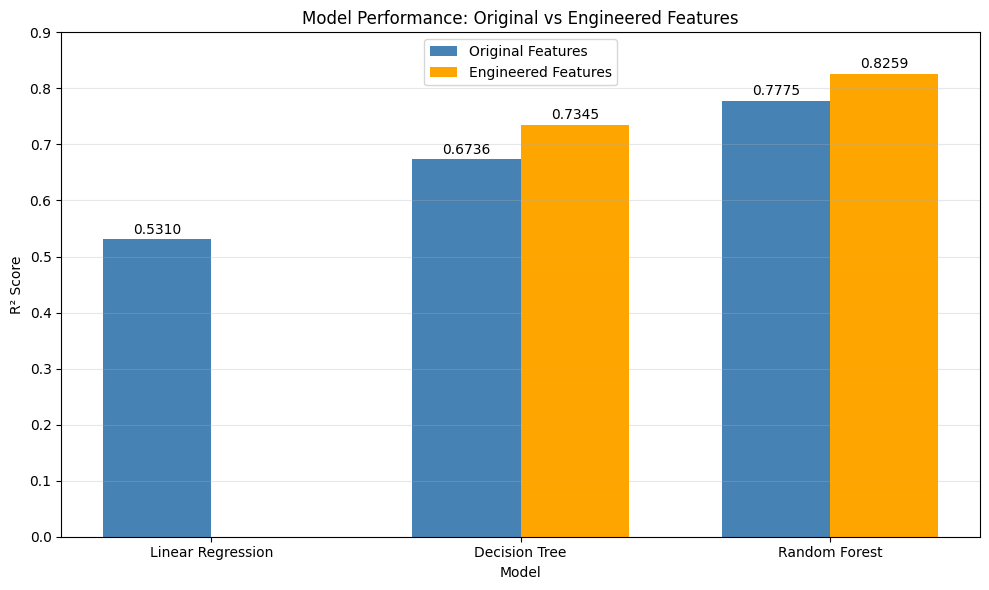

In [18]:

# ==========================================
# FINAL MODEL PERFORMANCE COMPARISON
# ==========================================

models = ["Linear Regression", "Decision Tree", "Random Forest"]

# Best R² scores from original models
original_r2 = [0.5310, 0.673584, 0.777501]

# Best R² scores with engineered features
engineered_r2 = [np.nan, 0.734518, 0.825943]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

# Original model bars
plt.bar(x - width/2, original_r2, width,
        label="Original Features", color="steelblue")

# Engineered model bars
plt.bar(x + width/2, engineered_r2, width,
        label="Engineered Features", color="orange")

# Add R² values above the bars
for i in range(len(models)):
    plt.text(x[i] - width/2, original_r2[i] + 0.01,
             f"{original_r2[i]:.4f}", ha="center")

    if not np.isnan(engineered_r2[i]):
        plt.text(x[i] + width/2, engineered_r2[i] + 0.01,
                 f"{engineered_r2[i]:.4f}", ha="center")

plt.xticks(x, models)
plt.ylabel("R² Score")
plt.xlabel("Model")
plt.title("Model Performance: Original vs Engineered Features")
plt.ylim(0, 0.9)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
